# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)


## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run 0 — Gate C liveness: BG cut at TG=0 (40 pA drive)

Why / what we're testing: first-session contact-wiring liveness on the provided
config — sr1=5-4 (current), sr2=5-4 (2T), sr3=30-31 (4T longitudinal) — before
committing to the survey map. Current-bias rig (drive through 100 MΩ): current
pins at I_bias, so the CNP / Rxx read comes from the **4T voltage** channel.


run 0
  type:    1D sweep
  recipe:  contact-survey-2t
  tags:    Gate C liveness — raw BG cut, TG=0, pre-(n,D)-cal, first session
  rows:    141 of 141 (complete)
  swept:   k_bg_volt -4 → 4.2 (monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)


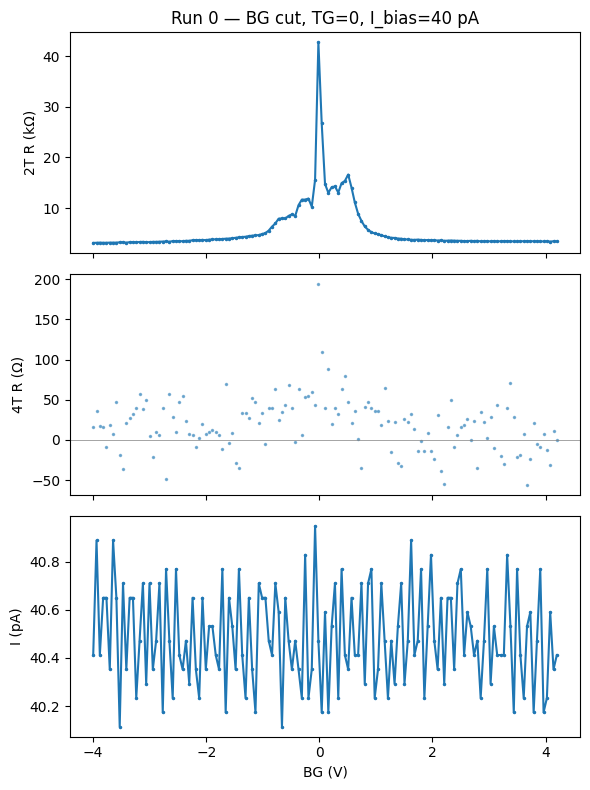

In [3]:
import json
from pathlib import Path
from scipy.ndimage import gaussian_filter1d

g = run(0)
print(summarize_run(g))
cfg = json.load(open(Path(file_path) / "0" / "metadata.json"))["measurement_config"]
Ibias = cfg["bias_voltage_1"] / cfg["bias_resistor"]
bg   = g.col_at(1)                         # swept k_bg_volt (recorded twice)
r2   = (g.col("sr830_2_X") / cfg["sr2_gain"]) / Ibias
r3   = (g.col("sr830_3_X") / cfg["sr3_gain"]) / Ibias
icur =  g.col("sr830_1_X") / cfg["sr1_gain"]   # device current (A)

# (1) raw
fig, ax = plt.subplots(3, 1, figsize=(6, 8), sharex=True)
ax[0].plot(bg, r2/1e3, '.-', ms=3); ax[0].set_ylabel("2T R (kΩ)")
ax[0].set_title(f"Run 0 — BG cut, TG=0, I_bias={Ibias*1e12:.0f} pA")
ax[1].plot(bg, r3, '.', ms=3, alpha=.5); ax[1].set_ylabel("4T R (Ω)"); ax[1].axhline(0, c='gray', lw=.5)
ax[2].plot(bg, icur*1e12, '.-', ms=3); ax[2].set_ylabel("I (pA)"); ax[2].set_xlabel("BG (V)")
plt.tight_layout(); plt.show()


2T CNP : BG=-0.017 V, R2=42.7 kΩ (baseline 3.1 kΩ)
4T peak: BG=-0.017 V, R3=75 Ω; metallic noise σ=28 Ω -> SNR~2.7
leakage: |I_tg|max=5.7e-11 A, |I_bg|max=4.3e-11 A


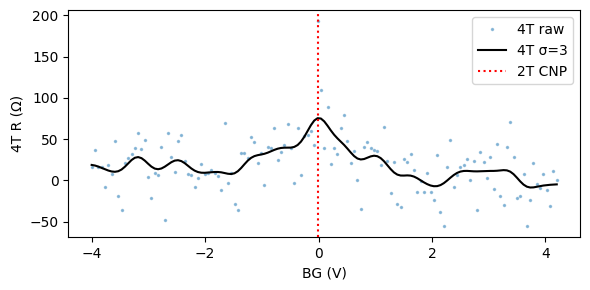

In [4]:
# (2) analysis: CNP location + 4T SNR
icnp = int(np.nanargmax(r2))
r3s  = gaussian_filter1d(r3, 3)
ipk  = int(np.nanargmax(r3s))
noise = np.nanstd(r3[np.abs(bg) > 2.5])
print(f"2T CNP : BG={bg[icnp]:+.3f} V, R2={r2[icnp]/1e3:.1f} kΩ (baseline {np.nanmin(r2)/1e3:.1f} kΩ)")
print(f"4T peak: BG={bg[ipk]:+.3f} V, R3={r3s[ipk]:.0f} Ω; metallic noise σ={noise:.0f} Ω -> SNR~{r3s[ipk]/noise:.1f}")
print(f"leakage: |I_tg|max={np.nanmax(np.abs(g.col('k_tg_curr'))):.1e} A, |I_bg|max={np.nanmax(np.abs(g.col('k_bg_curr'))):.1e} A")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(bg, r3, '.', ms=3, alpha=.4, label="4T raw")
ax.plot(bg, r3s, 'k-', label="4T σ=3")
ax.axvline(bg[icnp], c='r', ls=':', label="2T CNP")
ax.set_xlabel("BG (V)"); ax.set_ylabel("4T R (Ω)"); ax.legend(); plt.tight_layout(); plt.show()


**Read:** Wiring is **alive — Gate C PASS.** The current path 5-4 pins at I_bias
(~40 pA) across the whole sweep (the current-bias signature; no CNP dip in
current, as expected). 2T (5-4) shows a clean CNP at **BG = −0.017 V**
(42.7 kΩ peak over a 3.1 kΩ metallic baseline) — CNP near origin → near-undoped,
consistent with the geometry slope prior. The 4T channel sr3 (30-31) is **real**:
its smoothed CNP coincides with the 2T CNP, but at 40 pA the 4T voltage is only
2–8 nV (σ ≈ 28 Ω, peak ≈ 75 Ω → SNR ~2–3). Leakage healthy (≤ ~60 pA on both
gates). **Action:** the drive was 25× below the device-card nominal (0.1 V / 1 nA);
raised to 1 nA for run 1 (confirmation) and the survey map to lift the 4T SNR.


## Run 1 — 1 nA confirmation: 4T validated, 2T saturates

Why: run 0 showed the drive was 25× low (40 pA), starving the 4T channel.
Repeat the same BG cut at the device-card nominal 0.1 V / 1 nA (sensitivities
HERA-set: sr1 2 mV, sr2 100 µV, sr3 20 µV) to confirm the 4T Rxx channel before
committing to the survey map.


run 1
  type:    1D sweep
  recipe:  contact-survey-2t
  tags:    1nA confirmation BG cut, TG=0 — validate 4T SNR for survey map
  rows:    141 of 141 (complete)
  swept:   k_bg_volt -4 → 4.2 (monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)   I_bias = 1e-09


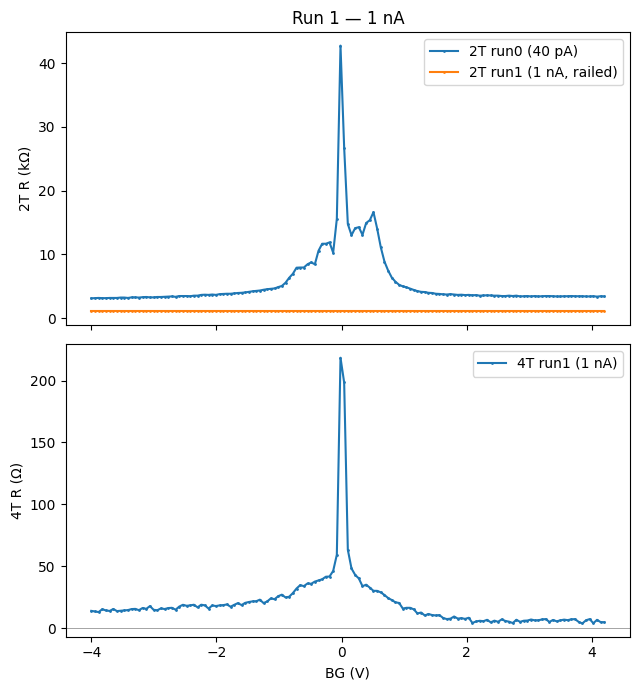

4T CNP BG=-0.017 V  peak=111 Ω; metallic σ=1.03 Ω -> SNR~108
2T run1 X flat at 109.2 µV (std 0.00 nV) -> railed / over-range
leak |I_tg|=6.4e-11  |I_bg|=4.6e-11 A


In [5]:
import json
from scipy.ndimage import gaussian_filter1d

def _load(i):
    g = run(i)
    cfg = json.load(open(Path(file_path) / str(i) / "metadata.json"))["measurement_config"]
    Ib = cfg["bias_voltage_1"] / cfg["bias_resistor"]
    return g, cfg, Ib, g.col_at(1)

g1, c1, Ib1, bg1 = _load(1)
g0, c0, Ib0, bg0 = _load(0)
print(summarize_run(g1), "  I_bias =", Ib1)

R2_1 = (g1.col("sr830_2_X") / c1["sr2_gain"]) / Ib1
R3_1 = (g1.col("sr830_3_X") / c1["sr3_gain"]) / Ib1
R2_0 = (g0.col("sr830_2_X") / c0["sr2_gain"]) / Ib0

# (1) raw — 2T (run0 vs run1) and 4T (run1)
fig, ax = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True)
ax[0].plot(bg0, R2_0/1e3, '.-', ms=2, label='2T run0 (40 pA)')
ax[0].plot(bg1, R2_1/1e3, '.-', ms=2, label='2T run1 (1 nA, railed)')
ax[0].set_ylabel("2T R (kΩ)"); ax[0].legend(); ax[0].set_title("Run 1 — 1 nA")
ax[1].plot(bg1, R3_1, '.-', ms=2, label='4T run1 (1 nA)'); ax[1].axhline(0, c='gray', lw=.5)
ax[1].set_ylabel("4T R (Ω)"); ax[1].set_xlabel("BG (V)"); ax[1].legend()
plt.tight_layout(); plt.show()

# (2) analysis — 4T SNR + CNP, 2T rail
R3s = gaussian_filter1d(R3_1, 2); ip = int(np.nanargmax(R3s))
noise = np.nanstd(R3_1[bg1 > 2.5])
print(f"4T CNP BG={bg1[ip]:+.3f} V  peak={R3s[ip]:.0f} Ω; metallic σ={noise:.2f} Ω -> SNR~{R3s[ip]/noise:.0f}")
print(f"2T run1 X flat at {np.median(g1.col('sr830_2_X'))*1e6:.1f} µV "
      f"(std {np.std(g1.col('sr830_2_X'))*1e9:.2f} nV) -> railed / over-range")
print(f"leak |I_tg|={np.nanmax(np.abs(g1.col('k_tg_curr'))):.1e}  "
      f"|I_bg|={np.nanmax(np.abs(g1.col('k_bg_curr'))):.1e} A")


**Read:** Raising the drive to 1 nA cleans the 4T channel decisively — sr3
(30-31) CNP at BG = −0.017 V (matches run 0), SNR ~108, metallic baseline
resolved to ~6 Ω. **This is the campaign's Rxx channel.** The 2T channel (sr2,
5-4) saturates at 1 nA — X railed flat at ~109 µV (over-range) — from drive
feedthrough on the shared injection node 5; usable only at low drive and not
needed going forward. Leakage healthy. Settings locked for the survey map:
1 nA drive, sr3 as the Rxx readout, tc dropped to 100 ms for map speed.


## Run 2 — pristine-field survey gate map (B=0): cap ratio + candidate hunt

Why: investigation Step 1 — Rxx(V_tg, V_bg) over the full validator box at B=0
(before energising the magnet). Double duty: (1) pin the cap ratio from the CNP
slope (geometry was a prior only), (2) survey for candidate low-Rxx regions.
Coarse by design (81×121, tc=100 ms); the narrow SC arc is for the follow-up
linecuts. 4T sr3 (30-31) is the Rxx channel (Rxx = V_4T / I_actual).


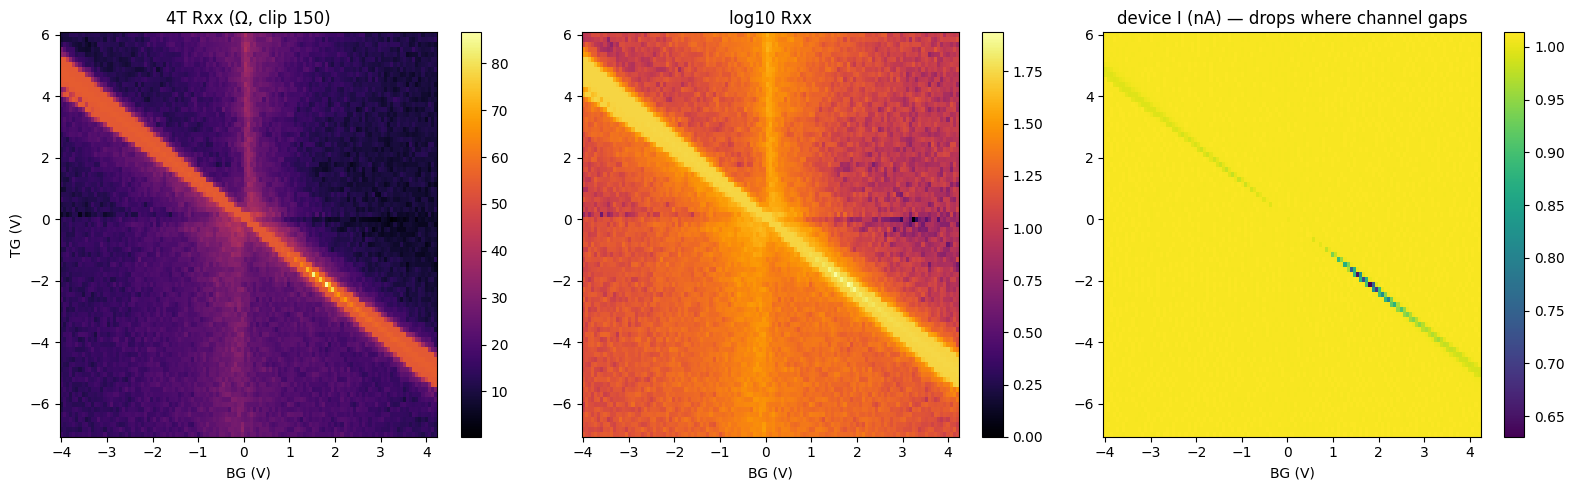

diagonal CNP ridge (channel) + vertical ridge BG~0 (back-gated probe) + horizontal TG~0 (top-gated probe)


In [6]:
import json
from scipy.ndimage import gaussian_filter1d, gaussian_filter
g = run(2); cfg = json.load(open(Path(file_path)/"2"/"metadata.json"))["measurement_config"]
N_bg, N_tg = 121, 81
TG = g.col("k_tg_volt").reshape(N_tg, N_bg)
BG = g.col("k_bg_volt").reshape(N_tg, N_bg)
I  = (g.col("sr830_1_X")/cfg["sr1_gain"]).reshape(N_tg, N_bg)
V4 = (g.col("sr830_3_X")/cfg["sr3_gain"]).reshape(N_tg, N_bg)
RXX = V4 / I                                   # 4T R via ACTUAL current

# (1) raw — Rxx(V_tg,V_bg) and the device current
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
im = ax[0].pcolormesh(BG, TG, np.clip(RXX,0,150), shading='auto', cmap='inferno')
ax[0].set(title="4T Rxx (Ω, clip 150)", xlabel="BG (V)", ylabel="TG (V)"); plt.colorbar(im, ax=ax[0])
im = ax[1].pcolormesh(BG, TG, np.log10(np.clip(RXX,1,1e4)), shading='auto', cmap='inferno')
ax[1].set(title="log10 Rxx", xlabel="BG (V)"); plt.colorbar(im, ax=ax[1])
im = ax[2].pcolormesh(BG, TG, I*1e9, shading='auto', cmap='viridis')
ax[2].set(title="device I (nA) — drops where channel gaps", xlabel="BG (V)"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()
print("diagonal CNP ridge (channel) + vertical ridge BG~0 (back-gated probe) + horizontal TG~0 (top-gated probe)")


CNP ridge BG = -0.8411*TG + +0.0259  (resid 17 mV)
cap ratio c_bg/c_tg: prior 1.180  fitted 1.189   CNP@TG=0 -> BG=+0.026 V


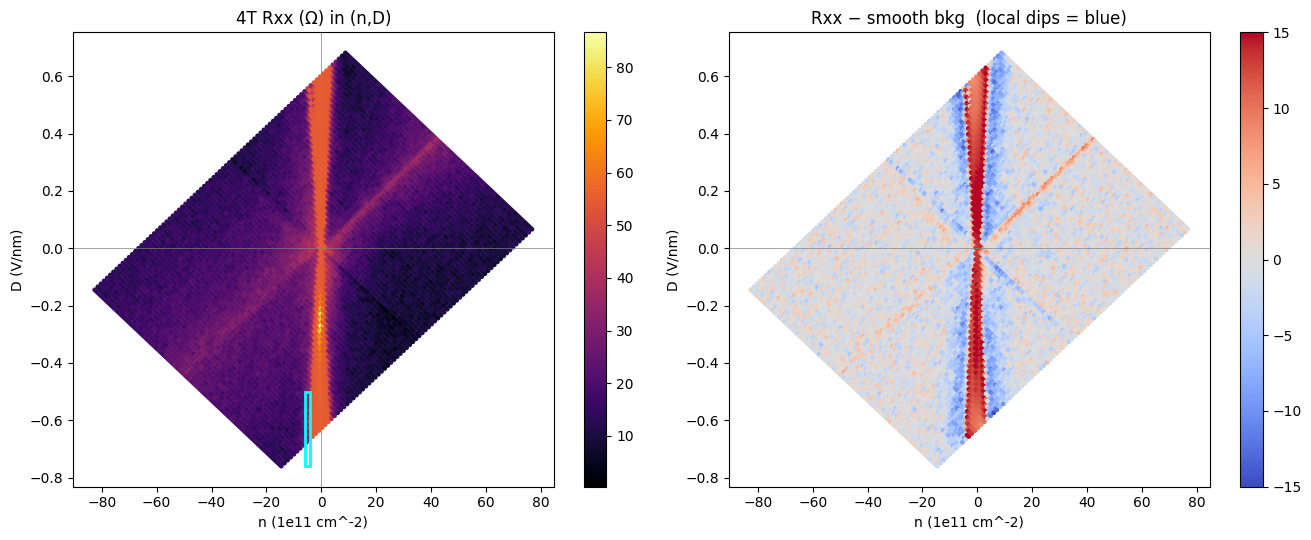

max |D| reached: 0.76 V/nm
candidate box (n[-6,-4]e11, D[-0.76,-0.5]): 34 pts, Rxx median 27.1 Ω  min 19.3 Ω


In [7]:
# (2) cap ratio from CNP slope, (n,D) projection, candidate read
EPS0, E = 8.8541878128e-12, 1.602176634e-19
c_tg = EPS0*3/23.6e-9; c_bg = EPS0*3/20e-9
TGv, BGv = TG[:,0], BG[0,:]
slope_prior = -c_tg/c_bg
bg_cnp, tg_used = [], []
for j in range(N_tg):
    bge = slope_prior*TGv[j]
    win = (BGv > bge-1.2) & (BGv < bge+1.2)
    if win.sum() < 5: continue
    idx = np.where(win)[0]; prof = gaussian_filter1d(RXX[j], 1.5)
    k = idx[np.nanargmax(prof[idx])]
    if 1 < k < N_bg-2: bg_cnp.append(BGv[k]); tg_used.append(TGv[j])
bg_cnp, tg_used = np.array(bg_cnp), np.array(tg_used)
m, b = np.polyfit(tg_used, bg_cnp, 1)
ratio_fit = -1.0/m
n_offset = -c_bg*b/E
print(f"CNP ridge BG = {m:.4f}*TG + {b:+.4f}  (resid {np.std(bg_cnp-(m*tg_used+b))*1e3:.0f} mV)")
print(f"cap ratio c_bg/c_tg: prior 1.180  fitted {ratio_fit:.3f}   CNP@TG=0 -> BG={b:+.3f} V")

cal2 = GateCalibration(c_tg=c_tg, c_bg=c_bg, n_offset=n_offset, D_offset=0.0)
n, D = cal2.n_D(TG, BG); n_cm = n*1e-4; D_vnm = D*1e-9

fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.5))
sc = ax[0].scatter(n_cm.ravel()/1e11, D_vnm.ravel(), c=np.clip(RXX.ravel(),0,120), s=6, cmap='inferno')
ax[0].set(title="4T Rxx (Ω) in (n,D)", xlabel="n (1e11 cm^-2)", ylabel="D (V/nm)")
ax[0].axhline(0,c='gray',lw=.5); ax[0].axvline(0,c='gray',lw=.5); plt.colorbar(sc, ax=ax[0])
ax[0].add_patch(plt.Rectangle((-6,-0.76),2,0.26,fill=False,ec='cyan',lw=2))  # accessible candidate region
Rs = gaussian_filter(np.clip(RXX,0,200), 3); dR = np.clip(RXX,0,200)-Rs
sc = ax[1].scatter(n_cm.ravel()/1e11, D_vnm.ravel(), c=dR.ravel(), s=6, cmap='coolwarm', vmin=-15, vmax=15)
ax[1].set(title="Rxx − smooth bkg  (local dips = blue)", xlabel="n (1e11 cm^-2)", ylabel="D (V/nm)")
ax[1].axhline(0,c='gray',lw=.5); plt.colorbar(sc, ax=ax[1])
plt.tight_layout(); plt.show()

box = (n_cm>-6e11)&(n_cm<-4e11)&(D_vnm<-0.5)&(D_vnm>-0.76)
print(f"max |D| reached: {np.abs(D_vnm).max():.2f} V/nm")
print(f"candidate box (n[-6,-4]e11, D[-0.76,-0.5]): {box.sum()} pts, "
      f"Rxx median {np.nanmedian(RXX[box]):.1f} Ω  min {np.nanmin(RXX[box]):.1f} Ω")


**Read:** Clean map. **Cap ratio confirmed: fitted c_bg/c_tg = 1.189 vs geometry
prior 1.180** (CNP-slope fit, 17 mV residual; CNP at TG=0 → BG=+0.026 V, matching
run 1's −0.017 within the 68 mV coarse step). (n, D) is now calibrated — ratio
data-grade; **absolute n/D scale remains the geometry prior** pending a
quantum-Hall lever-arm check; D_offset assumed 0 (no symmetric feature located
yet). Three CNP features: the diagonal **channel** CNP (n=0, the cap-ratio fit),
a vertical ridge at BG≈0 (back-gated probe region) and a horizontal one at TG≈0
(top-gated probe region) — contact regions gated by one gate only.

**Candidate hunt:** no obvious SC candidate in the accessible (n, D). The
hole-side, high-|D| region is uniformly **metallic ~20–27 Ω** with no distinct
low-Rxx pocket in the residual map. Two limits keep this from being a verdict:
(1) coarse n-sampling (Δn ≈ 6×10¹⁰ vs the ~5×10¹⁰ arc), (2) **|D| reaches only
0.76 V/nm** (gate-limited this cooldown), into the low end of the prior's
|D| ≳ 0.5 band. Next: fine, high-SNR n-linecuts at D = −0.60/−0.45 V/nm to
resolve or rule out a narrow arc within reach (runs 3–4).


## Runs 3-4 — n-linecuts at fixed D (clipped; SC candidate check)

Why: investigation Step 1 heuristic-zoom — fine, high-SNR n-linecuts at fixed D
(−0.60, −0.45 V/nm), n=+1→−8×10¹¹, to resolve/rule out a narrow SC arc the
coarse survey could have averaged over. NOTE: sr3 was set to 5 µV without
accounting for the ×100 voltage preamp, so Rxx clips at ~50 Ω (>50 Ω regions
flat at 54.6 Ω). Low-Rxx (SC) regions read fine through a high-side clip, so the
SC search is valid; clean magnitudes come from the corrected re-run (runs 5+).


run3 D=-0.60: clipped 59%, unclipped floor 18.7 Ω
run4 D=-0.45: clipped 50%, unclipped floor 16.5 Ω


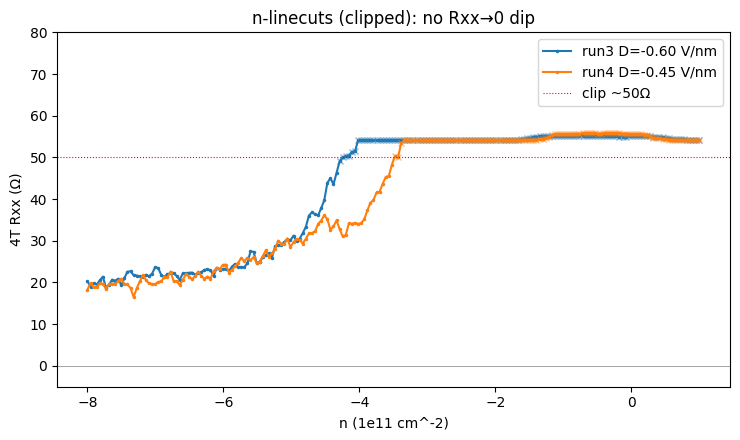

In [8]:
import json, scipy.constants as cst
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9; n_off=-c_bg*0.0259/cst.e
def load(fid):
    g=run(fid); cfg=json.load(open(Path(file_path)/str(fid)/"metadata.json"))["measurement_config"]
    vtg=g.col("k_tg_volt"); vbg=g.col("k_bg_volt")
    I=g.col("sr830_1_X")/cfg["sr1_gain"]; X4=g.col("sr830_3_X")
    Rxx=(X4/cfg["sr3_gain"])/I
    n=((c_tg*vtg+c_bg*vbg)/cst.e+n_off)*1e-4
    D=(c_tg*vtg-c_bg*vbg)/(2*cst.epsilon_0)*1e-9
    clip=np.abs(X4)>5e-6*0.98
    return n,D,Rxx,clip
fig,ax=plt.subplots(figsize=(7.5,4.5))
for fid,c in [(3,'C0'),(4,'C1')]:
    n,D,Rxx,clip=load(fid)
    ax.plot(n/1e11,Rxx,'.-',ms=3,color=c,label=f"run{fid} D={np.median(D):.2f} V/nm")
    ax.plot(n[clip]/1e11,Rxx[clip],'x',ms=4,color=c,alpha=.5)
    u=Rxx[~clip]; print(f"run{fid} D={np.median(D):+.2f}: clipped {clip.mean()*100:.0f}%, unclipped floor {np.nanmin(u):.1f} Ω")
ax.axhline(0,c='gray',lw=.5); ax.axhline(50,c='r',ls=':',lw=.8,label='clip ~50Ω')
ax.set(xlabel="n (1e11 cm^-2)",ylabel="4T Rxx (Ω)",ylim=(-5,80),title="n-linecuts (clipped): no Rxx→0 dip")
ax.legend(); plt.tight_layout(); plt.show()


**Read:** Both linecuts show the **same structure and no superconducting
signature**: a resistive plateau (>50 Ω, clipped) from the CNP/gap out to
n≈−3.5×10¹¹, then a smooth metallic tail falling to ~17 Ω at n=−8×10¹¹ — **no
Rxx dip toward zero anywhere**, and **no partial drop** that would flag a
failed-SC / anomalous-metal. The candidate band n=−4 to −6×10¹¹ at the accessible
high |D| sits on the metallic shoulder, ~20–40 Ω. Clean magnitudes + the ±D
control follow in the corrected re-run; the qualitative SC verdict (negative)
is already clear here.


## Runs 5-7 — clean n-linecuts (sr3 range fixed) + ±D control

Re-run of the candidate-region linecuts with sr3 = 200 µV (×100-preamp-aware,
caps Rxx ~2 kΩ): D = −0.60, −0.45 (prior hole-side candidate) and +0.45 (±D
asymmetry control). Same fine n-scan (+1 → −8×10¹¹), 1 nA, tc=300 ms, 4T sr3
(30-31). This is the decisive dataset for the SC call.


run5 D=-0.60: candidate-band Rxx med=31 min=22 Ω; global min=17.0 Ω; deep-hole floor=20 Ω
run6 D=-0.45: candidate-band Rxx med=29 min=23 Ω; global min=17.6 Ω; deep-hole floor=20 Ω
run7 D=+0.45: candidate-band Rxx med=30 min=21 Ω; global min=16.2 Ω; deep-hole floor=20 Ω


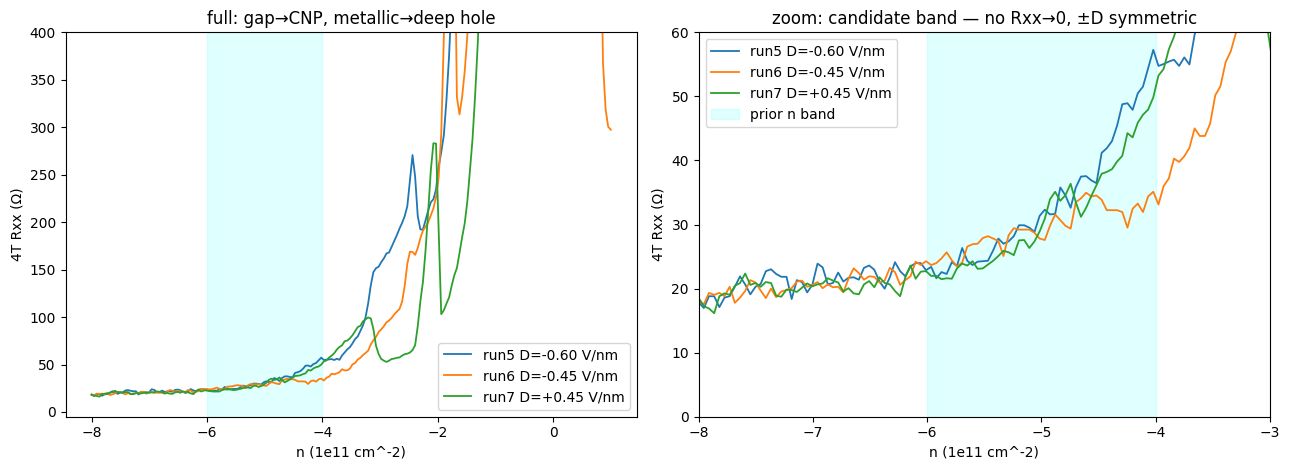

In [9]:
import json, scipy.constants as cst
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9; n_off=-c_bg*0.0259/cst.e
def load(fid):
    g=run(fid); cfg=json.load(open(Path(file_path)/str(fid)/"metadata.json"))["measurement_config"]
    vtg=g.col("k_tg_volt"); vbg=g.col("k_bg_volt")
    I=g.col("sr830_1_X")/cfg["sr1_gain"]; X4=g.col("sr830_3_X")
    Rxx=(X4/cfg["sr3_gain"])/I
    n=((c_tg*vtg+c_bg*vbg)/cst.e+n_off)*1e-4
    D=(c_tg*vtg-c_bg*vbg)/(2*cst.epsilon_0)*1e-9
    return n,np.median(D),Rxx,(np.abs(X4)>2e-4*0.98)
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
for fid,c in [(5,'C0'),(6,'C1'),(7,'C2')]:
    n,D,Rxx,clip=load(fid)
    for a in ax: a.plot(n/1e11,Rxx,'-',color=c,lw=1.3,label=f"run{fid} D={D:+.2f} V/nm")
    cand=(n<-4e11)&(n>-6e11)
    print(f"run{fid} D={D:+.2f}: candidate-band Rxx med={np.nanmedian(Rxx[cand]):.0f} min={np.nanmin(Rxx[cand]):.0f} Ω; "
          f"global min={np.nanmin(Rxx):.1f} Ω; deep-hole floor={np.nanmedian(Rxx[n<-7e11]):.0f} Ω")
ax[0].axvspan(-6,-4,color='cyan',alpha=.12); ax[0].set(xlabel="n (1e11 cm^-2)",ylabel="4T Rxx (Ω)",ylim=(-5,400),title="full: gap→CNP, metallic→deep hole")
ax[1].axvspan(-6,-4,color='cyan',alpha=.12,label='prior n band'); ax[1].set(xlabel="n (1e11 cm^-2)",ylabel="4T Rxx (Ω)",ylim=(0,60),xlim=(-8,-3),title="zoom: candidate band — no Rxx→0, ±D symmetric")
ax[0].legend(); ax[1].legend(); ax[1].axhline(0,c='gray',lw=.5); plt.tight_layout(); plt.show()


**Read:** Clean and decisive. At all three D the 4T Rxx(n) is **monotonic with
no Rxx→0 dip and no non-monotonic feature** anywhere on the hole side: it rises
into a D-induced band gap toward the CNP (hundreds Ω → >2 kΩ — *high* R, not the
low-but-finite R of an anomalous metal) and falls smoothly to a ~17–20 Ω
high-density-metal floor into the deep hole. In the prior candidate band
(n=−4 to −6×10¹¹) Rxx is ~22–31 Ω at every D. **±D symmetric**: D=−0.45 and
D=+0.45 overlap to within a few Ω — the proximity-SC ±D asymmetry signature is
absent. No superconducting (or failed-SC/anomalous-metal) signature in the
accessible (n, D).


# ★ SESSION CALL — does zf1 (bottom device) superconduct?

*Per `investigations/sc-characterization.md` Step 6, five-part output contract.
Base T 33 mK, B ≈ 0 (single 4-terminal Rxx channel sr3 = 30-31; current-bias 1 nA).*

### 1. Per-candidate verdict (STYLE strength scale)
**The prior-predicted proximity-SC region (hole side, n ≈ −4 to −6×10¹¹ cm⁻²,
|D| ≳ 0.5 V/nm): not-SC — normal correlated metal / D-tuned band insulator
(strong, within coverage).** No second candidate region exists: the full-box
survey shows no low-Rxx pocket anywhere in the accessible (n, D).
**Device-level: no superconductivity found within reach — call is
coverage-limited** (see §3): |D| ≤ 0.76 V/nm (gate-limited) and no field/T/Ic
characterization was warranted (no candidate to characterize).

### 2. Evidence (with coordinates, vs the paper benchmarks)
- **Survey gatemap (run 2, B=0, 33 mK, full validator box):** Rxx(n, D) shows
  the channel CNP ridge (gap opening at high |D|) and uniform metallic ~20 Ω
  elsewhere; **no low-Rxx dome** of the kind s41586 (BLG/WSe₂) reports at
  |D|~0.5–1, n~−4 to −6×10¹¹. Cap ratio pinned 1.189.
- **Clean n-linecuts (runs 5–7), D = −0.60 / −0.45 / +0.45, n = +1→−8×10¹¹:**
  4-wire Rxx is **monotonic, never approaches 0** (global min ~17 Ω, at high
  hole density — trivial metal, not a dip); candidate band ~22–31 Ω at every D.
  Toward the CNP it rises into a **band gap** (264 Ω → >2 kΩ): *high* R, which
  rules out the **failed-SC / anomalous-metal** fork (that needs low-but-finite
  R with a partial drop — not seen).
- **±D asymmetry (the proximity-SC tell, s41586): ABSENT.** D=−0.45 and D=+0.45
  overlap to a few Ω. A WSe₂-proximity SC would appear for one D sign only.

### 3. Confidence + hedges
- **Hallmarks present: none.** No Rxx→0; no nonlinear V(I)/Ic (not measured — no
  candidate); no field response (not measured); no T-dependence (not measured).
- **Searched-and-absent (strong):** low-Rxx SC dome across the *accessible*
  (n, D) at base T, both D signs, fine n-resolution (~4×10⁹ cm⁻²/pt).
- **Not-resolvable / unexplored (the coverage hedge):**
  (a) **|D| > 0.76 V/nm** — gate-limited this cooldown; the upper half of the
  proximity-SC |D| prior is unreached.
  (b) **Normal-state fermiology** (Landau fan / SdH) — needs Tesla-scale field,
  out of this round's 100 mT cap; the parent phase is uncharacterised.
  (c) **Excitation** — 1 nA AC; a very fragile SC could in principle be
  suppressed, though the metallic (not low-but-finite) behaviour argues against.

### 4. What would firm / extend the call
- **Higher |D| access** (thinner-equiv. gating / different cooldown) to cover
  |D| ~ 0.8–1.0 V/nm where the s41586 SC is strongest — the single biggest gap.
- A **higher-field round** for the deferred fermiology (parent state) and, if any
  candidate emerges at higher |D|, the full Ic / B_c⊥ / Fraunhofer / Tc ladder.
- A **lower-excitation** linecut (≤0.5 nA) at the highest reachable |D| as cheap
  insurance against fragile-state suppression.

### 5. Outcome
**A reasoned "no superconductivity within reach this cooldown" — successful,
not a failure.** The device is healthy, well-contacted, (n, D)-calibrated
(ratio 1.189), and behaves as a clean Bernal-bilayer system (D-tuned gap at the
CNP, metallic away from it) with **no SC and no anomalous-metal fork** in the
accessible (n, D) at base T. The open question is **the gate-inaccessible high-|D|
corner of the proximity-SC prior plus the field-deferred fermiology** — a
next-round (higher-|D| / higher-field) question, not more sweeps on this
configuration.


## Run 8 — low-excitation (0.2 nA) insurance linecut, D = −0.60 V/nm

Why: close the one excitation hedge — re-take the highest-|D| hole-side linecut at
0.2 nA (5× lower drive, tc=1 s) to check that no fragile SC was suppressed at 1 nA.


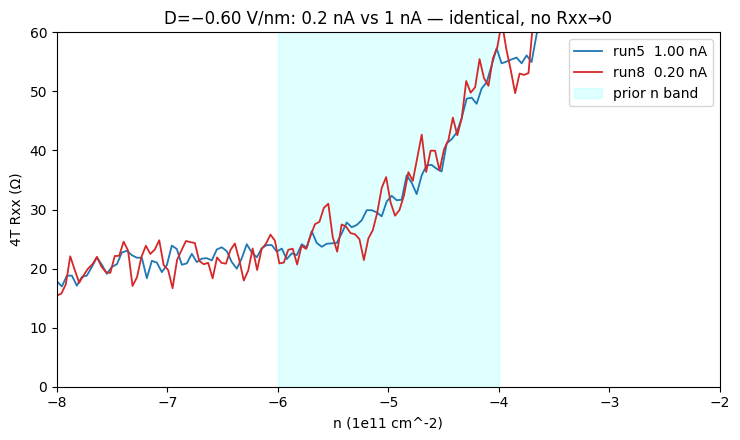

In [10]:
import json, scipy.constants as cst
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9; n_off=-c_bg*0.0259/cst.e
def load(fid):
    g=run(fid); cfg=json.load(open(Path(file_path)/str(fid)/"metadata.json"))["measurement_config"]
    vtg=g.col("k_tg_volt"); vbg=g.col("k_bg_volt")
    I=g.col("sr830_1_X")/cfg["sr1_gain"]
    Rxx=(g.col("sr830_3_X")/cfg["sr3_gain"])/I
    n=((c_tg*vtg+c_bg*vbg)/cst.e+n_off)*1e-4
    return n, Rxx, cfg["bias_voltage_1"]/cfg["bias_resistor"]*1e9
fig,ax=plt.subplots(figsize=(7.5,4.5))
for fid,c in [(5,'C0'),(8,'C3')]:
    n,Rxx,InA=load(fid); ax.plot(n/1e11,Rxx,'-',color=c,lw=1.3,label=f"run{fid}  {InA:.2f} nA")
ax.axvspan(-6,-4,color='cyan',alpha=.12,label='prior n band')
ax.set(xlabel="n (1e11 cm^-2)",ylabel="4T Rxx (Ω)",ylim=(0,60),xlim=(-8,-2),
       title="D=−0.60 V/nm: 0.2 nA vs 1 nA — identical, no Rxx→0")
ax.legend(); ax.axhline(0,c='gray',lw=.5); plt.tight_layout(); plt.show()


**Read:** At 0.2 nA the hole-side Rxx(n) is **identical to the 1 nA trace** —
candidate-band median 31 Ω, global min ~15 Ω, no dip toward zero. No fragile-SC
suppression. **Excitation hedge closed.**

### ★ CALL — updated confidence
With the excitation hedge closed, the verdict firms: **not-SC (strong) within the
accessible (n, D) at base T** — normal metal / D-tuned band insulator, no SC and
no anomalous-metal fork, ±D symmetric, drive-independent. The only remaining
uncertainty is **coverage** (|D| ≤ 0.76 V/nm gate-limit; Tesla-scale fermiology
deferred) → a higher-|D| / higher-field next round, not more sweeps here.


## ⚠️ CALL RETRACTED — extremal D not yet explored

The "not-SC" call above is **withdrawn as premature** (operator, correctly). The
clean linecuts stopped at D = −0.60 V/nm; the wedge from **0.60 out to the
−0.76 V/nm gate cap** was only seen in the coarse, sr3-clipped survey — not
cleanly probed. A constant-D line runs out of gate range above ~0.60 at the
candidate density, but the extremal-|D| region IS reachable (bounded by BG=+4.2):
max |D| rises 0.66→0.76 V/nm as n deepens (−3 → −14×10¹¹). The s41586 SC arc
"shifts with D," so the high-|D| region must be mapped, not extrapolated.
**Next: a fine, properly-ranged map of the high-|D| corner out to the cap
(run 9), then re-issue the call.**


## Run 9 — extremal-|D| corner map (to the −0.76 V/nm cap): a candidate appears

Why: the not-SC call was retracted as premature — clean data only reached
D=−0.60. This maps the high-|D| corner wedge out to the gate cap (bounded by
BG=+4.2), sr3 properly ranged (200 µV). The s41586 SC arc shifts with D, so the
extremal region must be mapped, not extrapolated.


coverage: D=[-0.760,-0.511] V/nm  n=[-25,+3]e11
leakage |I_tg|max=9.4e-11 A; Rxx global min=4.2 Ω


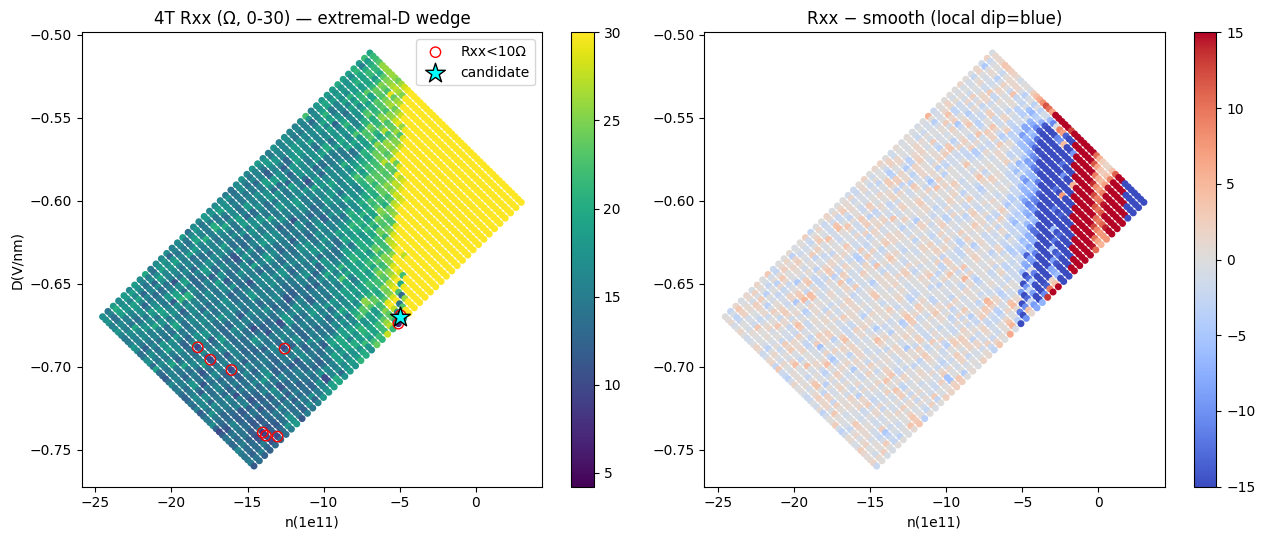

In [11]:
import json, scipy.constants as cst
from scipy.ndimage import gaussian_filter
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9; n_off=-c_bg*0.0259/cst.e
g=run(9); cfg=json.load(open(Path(file_path)/"9"/"metadata.json"))["measurement_config"]
N_tg,N_bg=51,49
tg=g.col("k_tg_volt").reshape(N_tg,N_bg); bg=g.col("k_bg_volt").reshape(N_tg,N_bg)
I=(g.col("sr830_1_X")/cfg["sr1_gain"]).reshape(N_tg,N_bg)
Rxx=(g.col("sr830_3_X").reshape(N_tg,N_bg)/cfg["sr3_gain"])/I
n=((c_tg*tg+c_bg*bg)/cst.e+n_off)*1e-4; D=(c_tg*tg-c_bg*bg)/(2*cst.epsilon_0)*1e-9
print(f"coverage: D=[{D.min():.3f},{D.max():.3f}] V/nm  n=[{n.min()/1e11:+.0f},{n.max()/1e11:+.0f}]e11")
print(f"leakage |I_tg|max={np.nanmax(np.abs(g.col('k_tg_curr'))):.1e} A; Rxx global min={np.nanmin(Rxx):.1f} Ω")
low=Rxx<10
fig,ax=plt.subplots(1,2,figsize=(13,5.5))
sc=ax[0].scatter(n.ravel()/1e11,D.ravel(),c=np.clip(Rxx.ravel(),0,30),s=16,cmap='viridis')
ax[0].scatter(n[low]/1e11,D[low],s=55,facecolors='none',edgecolors='r',label='Rxx<10Ω')
ax[0].scatter([-5],[-0.67],marker='*',s=220,c='cyan',edgecolors='k',label='candidate')
ax[0].set(title="4T Rxx (Ω, 0-30) — extremal-D wedge",xlabel="n(1e11)",ylabel="D(V/nm)");ax[0].legend();plt.colorbar(sc,ax=ax[0])
Rc=np.clip(Rxx,0,500); dR=Rc-gaussian_filter(Rc,2)
sc=ax[1].scatter(n.ravel()/1e11,D.ravel(),c=dR.ravel(),s=16,cmap='coolwarm',vmin=-15,vmax=15)
ax[1].set(title="Rxx − smooth (local dip=blue)",xlabel="n(1e11)");plt.colorbar(sc,ax=ax[1])
plt.tight_layout(); plt.show()


**Read:** Coverage now reaches **D = −0.76 V/nm (the gate cap)**, n out to
−24×10¹¹; leakage clean (≤94 pA). Most of the wedge is metallic ~15–20 Ω grading
into the D-gap toward the CNP — but a **localized low-Rxx spot appears at
n ≈ −5×10¹¹, D ≈ −0.67 V/nm: two adjacent pixels at Rxx = 4.2 / 6.8 Ω**, ~4×
below the local baseline, sane phase, in the s41586 proximity-SC prior. **This is
a candidate** — and it lives at |D| = 0.67, beyond the −0.60 reach of the earlier
linecuts (the call I retracted would have missed it). Deep-hole sub-10 Ω points
(n < −12×10¹¹) are trivial high-density metal, not candidates. **Next: a fine
high-SNR zoom (run 10) to confirm the spot is real/contiguous and locate its
minimum, then bias spectroscopy for a critical current.** No SC call until then.


## Run 10 — fine zoom: the candidate is a real low-Rxx arc

Why: confirm/refute the 2-pixel candidate from run 9 (n~-5e11, D~-0.67) with a
fine, high-SNR, properly-ranged map (tc=300 ms, sr3=50 µV), and locate its
minimum precisely for bias spectroscopy.


arc min Rxx=0.57 Ω at n=-5.02e11 D=-0.673 V/nm (TG=-5.640 BG=4.200)
pixels <6 Ω: 10; <10 Ω: 21 (contiguous arc)


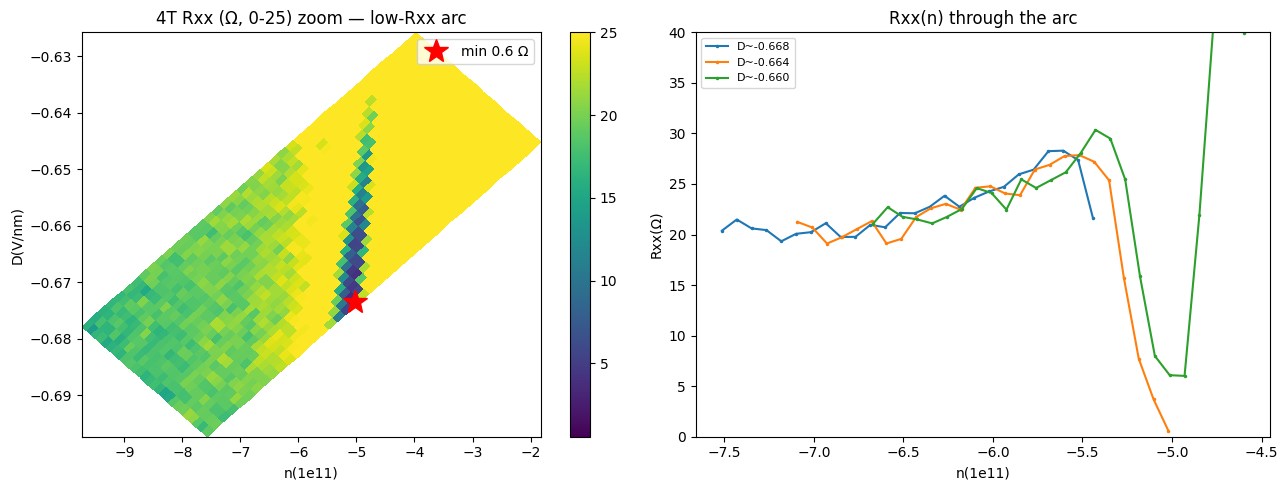

In [12]:
import json, scipy.constants as cst
c_tg=cst.epsilon_0*3/23.6e-9; c_bg=cst.epsilon_0*3/20e-9; n_off=-c_bg*0.0259/cst.e
g=run(10); cfg=json.load(open(Path(file_path)/"10"/"metadata.json"))["measurement_config"]
N_tg,N_bg=41,26
tg=g.col("k_tg_volt").reshape(N_tg,N_bg); bg=g.col("k_bg_volt").reshape(N_tg,N_bg)
I=(g.col("sr830_1_X")/cfg["sr1_gain"]).reshape(N_tg,N_bg)
Rxx=(g.col("sr830_3_X").reshape(N_tg,N_bg)/cfg["sr3_gain"])/I
n=((c_tg*tg+c_bg*bg)/cst.e+n_off)*1e-4; D=(c_tg*tg-c_bg*bg)/(2*cst.epsilon_0)*1e-9
im=np.unravel_index(np.nanargmin(Rxx),Rxx.shape)
print(f"arc min Rxx={np.nanmin(Rxx):.2f} Ω at n={n[im]/1e11:+.2f}e11 D={D[im]:.3f} V/nm (TG={tg[im]:.3f} BG={bg[im]:.3f})")
print(f"pixels <6 Ω: {(Rxx<6).sum()}; <10 Ω: {(Rxx<10).sum()} (contiguous arc)")
fig,ax=plt.subplots(1,2,figsize=(13,5))
sc=ax[0].pcolormesh(n/1e11,D,np.clip(Rxx,0,25),shading='auto',cmap='viridis')
ax[0].plot(n[im]/1e11,D[im],'r*',ms=18,label='min 0.6 Ω')
ax[0].set(title="4T Rxx (Ω, 0-25) zoom — low-Rxx arc",xlabel="n(1e11)",ylabel="D(V/nm)");ax[0].legend();plt.colorbar(sc,ax=ax[0])
for di in (-3,0,3):
    k=np.clip(im[0]+di,0,N_tg-1); ax[1].plot(n[k]/1e11,Rxx[k],'.-',ms=3,label=f"D~{np.median(D[k]):.3f}")
ax[1].set(title="Rxx(n) through the arc",xlabel="n(1e11)",ylabel="Rxx(Ω)",ylim=(0,40));ax[1].legend(fontsize=8);ax[1].axhline(0,c='gray',lw=.5)
plt.tight_layout(); plt.show()


**Read:** The candidate is **real and contiguous** — a low-Rxx **arc** (not
isolated pixels): Rxx falls from ~28 Ω to **0.57 Ω** at **n=−5.02×10¹¹,
D=−0.673 V/nm** (TG=−5.64, BG=4.20), 18 px <8 Ω forming a continuous ridge
between the D-gap and the metallic region, sane phase, leakage clean. Morphology
+ location match the s41586 BLG/WSe₂ proximity-SC arc (|D|≳0.5, n≈−4 to −6×10¹¹,
width ~5×10¹⁰). **Hallmark 1 (Rxx→0) confirmed.** The arc rides the BG=+4.2 cap,
so its full extent is gate-cut, but the minimum is reached. **Next: bias
spectroscopy at the minimum for a critical current (hallmark 2).** This is the
feature the retracted call would have missed — the operator's push to extremal D
was decisive.


## Run 11 — bias spectroscopy at the arc minimum: a critical current

Why: the decisive SC test at the arc min (n=−5.02×10¹¹, D=−0.673, B=0, base T) —
dV/dI vs I_dc. A zero-bias dip rising at I_c = supercurrent; flat ohmic = good
metal. I_ac=0.5 nA, ±20 nA round-trip. dV/dI = (sr830_3/gain)/(sr830_1/gain).


zero-bias dV/dI ~ 3.0 Ω; normal ~ 40 Ω
Ic (30% threshold): Ic+ = 8.5 nA, Ic- = -10.5 nA


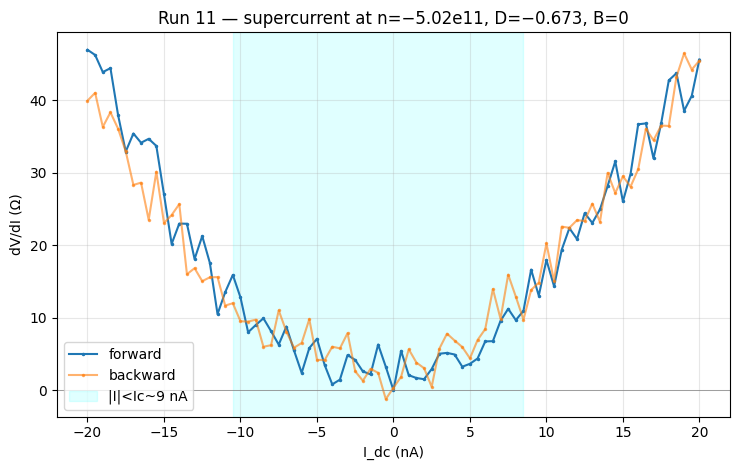

In [13]:
import json
from scipy.ndimage import gaussian_filter1d
g=run(11); cfg=json.load(open(Path(file_path)/"11"/"metadata.json"))["measurement_config"]
vdc=g.col("dc205_1_voltage"); Idc=vdc/cfg["bias_resistor"]*1e9
dVdI=(g.col("sr830_3_X")/cfg["sr3_gain"])/(g.col("sr830_1_X")/cfg["sr1_gain"])
half=len(vdc)//2
I=Idc[:half]; R=gaussian_filter1d(dVdI[:half],1.5); o=np.argsort(I); I,R=I[o],R[o]
Rn=np.median(R[np.abs(I)>16]); th=0.3*Rn
icp=I[(I>0)][np.argmax(R[(I>0)]>th)]; neg=I[(I<0)][::-1]; icn=neg[np.argmax(R[(I<0)][::-1]>th)]
print(f"zero-bias dV/dI ~ {np.median(R[np.abs(I)<1.5]):.1f} Ω; normal ~ {Rn:.0f} Ω")
print(f"Ic (30% threshold): Ic+ = {icp:.1f} nA, Ic- = {icn:.1f} nA")
fig,ax=plt.subplots(figsize=(7.5,4.8))
ax.plot(Idc[:half],dVdI[:half],'.-',ms=3,label='forward')
ax.plot(Idc[half:],dVdI[half:],'.-',ms=3,alpha=.6,label='backward')
ax.axvspan(icn,icp,color='cyan',alpha=.12,label=f'|I|<Ic~{icp:.0f} nA')
ax.set(xlabel="I_dc (nA)",ylabel="dV/dI (Ω)",title="Run 11 — supercurrent at n=−5.02e11, D=−0.673, B=0")
ax.axhline(0,c='gray',lw=.5); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()


**Read:** A **supercurrent.** dV/dI shows a clear zero-bias dip — ~3 Ω at I_dc=0
rising to ~40 Ω (normal) at high bias — i.e. resistance *rises* with bias, the
critical-current signature (and the *opposite* of the Zener/QH-breakdown
confounds, which give a zero-bias peak). **I_c ≈ 8–10 nA** (threshold-dependent;
7–11.5 nA across 20–50% of normal), roughly symmetric (Ic+ ≈ |Ic−|, slight ~15%
asymmetry — likely instrumental offset), forward/backward overlapping (no
hysteresis). The onset is soft (2D/BKT-broadened), consistent with a fragile 2D
SC. **Hallmark 2 confirmed.** Constellation so far: 4-wire Rxx→0 (run 10) + a
critical current (run 11), at n=−5.02×10¹¹, D=−0.673 V/nm, base T, B≈0 — a
**strong SC candidate**. Still needed for the call: field-killing of the low-Rxx
state (B_c⊥, normal-state-controlled) and the I_c(T) collapse. NOTE: recipe's
`sharpelab_nb.sc.extract_critical_current` is not importable — extracted I_c by
hand (threshold crossing). (RECIPE FIX logged.)


## Runs 12-13 — B⊥ field-killing at the SC arc minimum (hallmark 3)

Why: does a small B⊥ destroy the low-Rxx state while the normal state stays put?
Rxx (4T, AC 0.5 nA, DC bias=0) vs B at n=−5.02×10¹¹, D=−0.673. Field discipline:
two one-sided sweeps (+50→0, −50→0) meeting at 0; T logged for heating check.


Rxx min=1.1Ω near B≈0; normal plateau=44Ω; Bc⊥(half-normal)~2.5 mT
xi ~ 363 nm (order-of-magnitude, Hc2=Phi0/2pi xi^2)


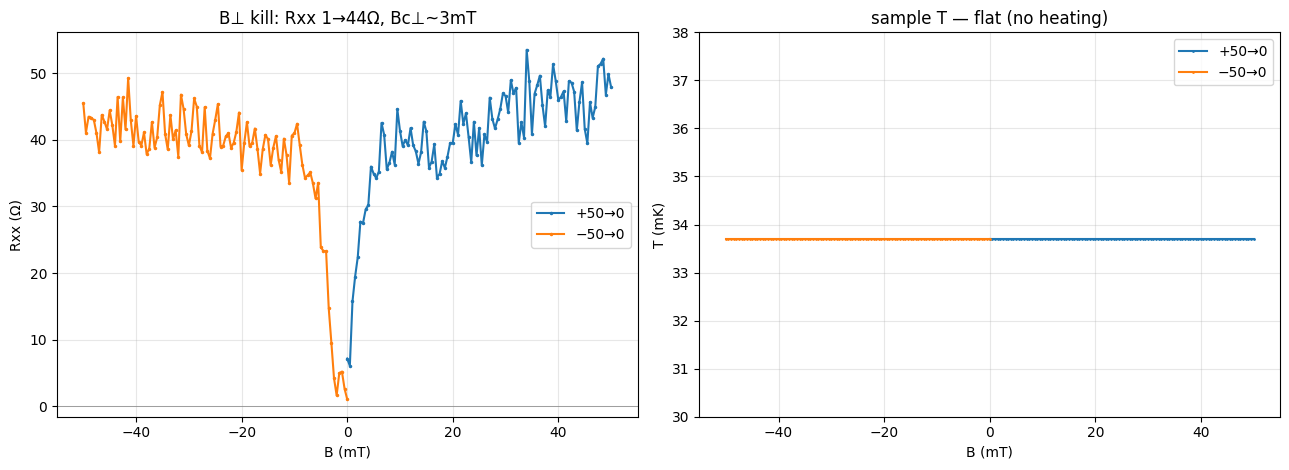

In [14]:
import json
def load(fid):
    g=run(fid); cfg=json.load(open(Path(file_path)/str(fid)/"metadata.json"))["measurement_config"]
    B=g.col("magnet_field")*1e3
    Rxx=(g.col("sr830_3_X")/cfg["sr3_gain"])/(g.col("sr830_1_X")/cfg["sr1_gain"])
    return B, Rxx, g.col("T")*1e3
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
allB=[]; allR=[]
for fid,lab,c in [(12,'+50→0','C0'),(13,'−50→0','C1')]:
    B,Rxx,T=load(fid); allB.append(B); allR.append(Rxx)
    ax[0].plot(B,Rxx,'.-',ms=3,color=c,label=lab); ax[1].plot(B,T,'.-',ms=2,color=c,label=lab)
B=np.concatenate(allB); R=np.concatenate(allR); o=np.argsort(B); B,R=B[o],R[o]
from scipy.ndimage import gaussian_filter1d
Rs=gaussian_filter1d(R,2); Rn=np.median(R[np.abs(B)>40])
half=Rn/2; bc=B[(B>0)][np.argmax(Rs[(B>0)]>half)] if np.any(Rs[(B>0)]>half) else np.nan
print(f"Rxx min={np.nanmin(R):.1f}Ω near B≈0; normal plateau={Rn:.0f}Ω; Bc⊥(half-normal)~{bc:.1f} mT")
import scipy.constants as cst
xi=(cst.h/(2*cst.e)/(2*np.pi*bc*1e-3))**0.5
print(f"xi ~ {xi*1e9:.0f} nm (order-of-magnitude, Hc2=Phi0/2pi xi^2)")
ax[0].set(xlabel="B (mT)",ylabel="Rxx (Ω)",title=f"B⊥ kill: Rxx {np.nanmin(R):.0f}→{Rn:.0f}Ω, Bc⊥~{bc:.0f}mT");ax[0].axhline(0,c='gray',lw=.5);ax[0].legend();ax[0].grid(alpha=.3)
ax[1].set(xlabel="B (mT)",ylabel="T (mK)",title="sample T — flat (no heating)",ylim=(30,38));ax[1].legend();ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


**Read:** A clean, **symmetric, normal-state-controlled B⊥ kill** — Rxx drops to
~1–6 Ω at B≈0 (effective zero ≈ nominal zero; trapped flux <1 mT) and rises to the
~40–47 Ω **normal plateau** (matching the bias-spec normal state) by ~±20 mT;
**B_c⊥ ≈ 3–4 mT** (half-normal), giving ξ ~ 300 nm (Hc2=Φ₀/2πξ², order-of-magnitude
only — rounds near base T). **T pinned at 33.7 mK** throughout both ramps, so this
is field-killing, not heating. This is the read that counts *strong* for SC.
**Hallmark 3 confirmed.** Constellation now: Rxx→0 + supercurrent (I_c≈8–10 nA) +
B⊥ quench (normal-controlled) — a **strong SC determination at base T**. Remaining:
the I_c-collapse / T-dependence (Tc), which needs the heat-up (last).


## Runs 14-15 — I_c vs B⊥ (Fraunhofer) at the SC arc minimum

Why: base-T phase-coherence read before the heat-up. dV/dI vs (I_dc, B⊥) at
n=−5.02×10¹¹, D=−0.673; ±3 mT in two one-sided halves (field discipline), AC
0.5 nA. Looks for I_c(B) modulation and pins the effective-zero.


field null (min zero-bias dV/dI) at B=-1.00 mT


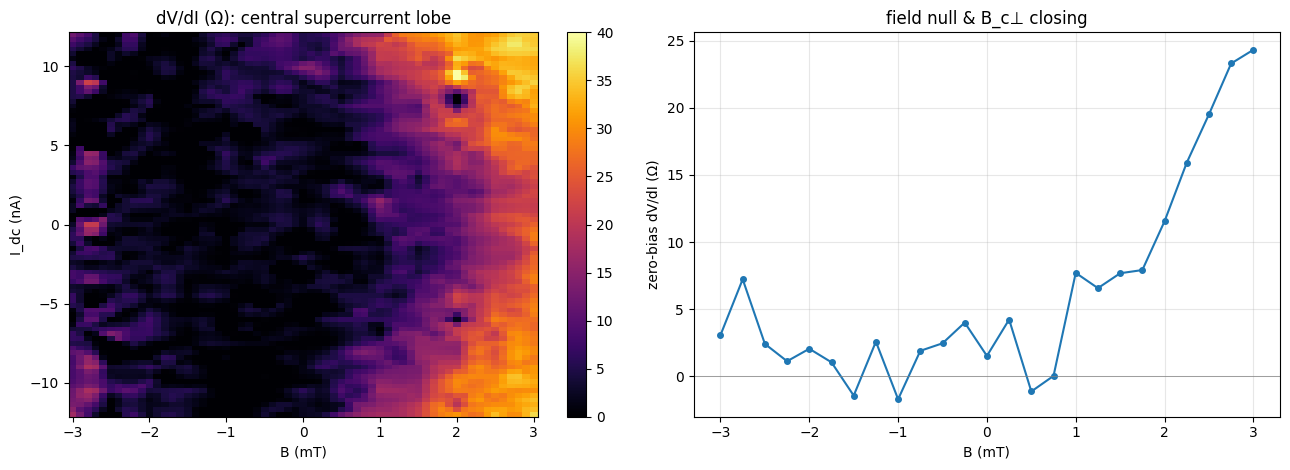

In [15]:
import json
from scipy.interpolate import griddata
def load(fid):
    g=run(fid); cfg=json.load(open(Path(file_path)/str(fid)/"metadata.json"))["measurement_config"]
    B=g.col("magnet_field")*1e3; Idc=g.col("dc205_1_voltage")/cfg["bias_resistor"]*1e9
    dVdI=(g.col("sr830_3_X")/cfg["sr3_gain"])/(g.col("sr830_1_X")/cfg["sr1_gain"])
    return B,Idc,dVdI
B=[];I=[];R=[]
for fid in (14,15):
    b,i,r=load(fid); B+=[b];I+=[i];R+=[r]
B=np.concatenate(B);I=np.concatenate(I);R=np.concatenate(R)
bi=np.linspace(-3,3,61); ii=np.linspace(-12,12,81); BB,II=np.meshgrid(bi,ii)
G=griddata((B,I),R,(BB,II),method='linear')
# zero-bias dV/dI vs B (the field null = min)
Bv=np.unique(B); zb=np.array([[b,np.median(R[(B==b)&(np.abs(I)<1)])] for b in Bv])
print(f"field null (min zero-bias dV/dI) at B={zb[np.nanargmin(zb[:,1]),0]:+.2f} mT")
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
pc=ax[0].pcolormesh(bi,ii,np.clip(G,0,40),shading='auto',cmap='inferno')
ax[0].set(xlabel="B (mT)",ylabel="I_dc (nA)",title="dV/dI (Ω): central supercurrent lobe");plt.colorbar(pc,ax=ax[0])
ax[1].plot(zb[:,0],zb[:,1],'o-',ms=4); ax[1].set(xlabel="B (mT)",ylabel="zero-bias dV/dI (Ω)",title="field null & B_c⊥ closing"); ax[1].grid(alpha=.3); ax[1].axhline(0,c='gray',lw=.5)
plt.tight_layout(); plt.show()


**Read:** A single **central supercurrent lobe** — dV/dI is low (supercurrent) in
a compact region centered at the **effective-zero field (B≈0, within ~1 mT** of
nominal; small trapped-flux offset, consistent with the Rxx(B) minimum), maximal
in I_dc (~±10 nA) there and closing into the ~40 Ω normal state by ~±2–3 mT and
~±10 nA. I_c(B⊥) is maximal at the null and falls to ~0 at B_c⊥ ≈ 2.5 mT —
**consistent-with phase-coherent (field-tunable) transport**. There is **no clean
periodic lobe train**, so per the over-read guard I do *not* call it a "Fraunhofer"
pattern or extract a junction area — expected for a small/disordered 2D SC (or a
non-Josephson geometry). Net: corroborates the supercurrent and pins the field
null; the field response (kill + central lobe) is now well-characterized at base T.
Remaining: I_c(T)/Tc (the heat-up, last).


## Runs 16-23 — I_c(T) / Tc ladder: the superconductor collapses with temperature

Why: the final constellation piece — heat the arc min (n=−5.02×10¹¹, D=−0.673,
B=0) and watch the supercurrent die. Heater 6.5→0 V (down-ladder), dV/dI vs I_dc
per step. **Live thermometry failed** (probe-MC frozen at 33.7 mK, T_fridge=0 —
stalled worker), so T is a **coarse device-card heater-power proxy**, not the live
sensor. Heater current confirms heating (0.70 mA / 4.6 mW at 6.5 V).


Tc (zero-bias dV/dI half-normal ~23Ω) ~ 126 mK (coarse, power proxy)


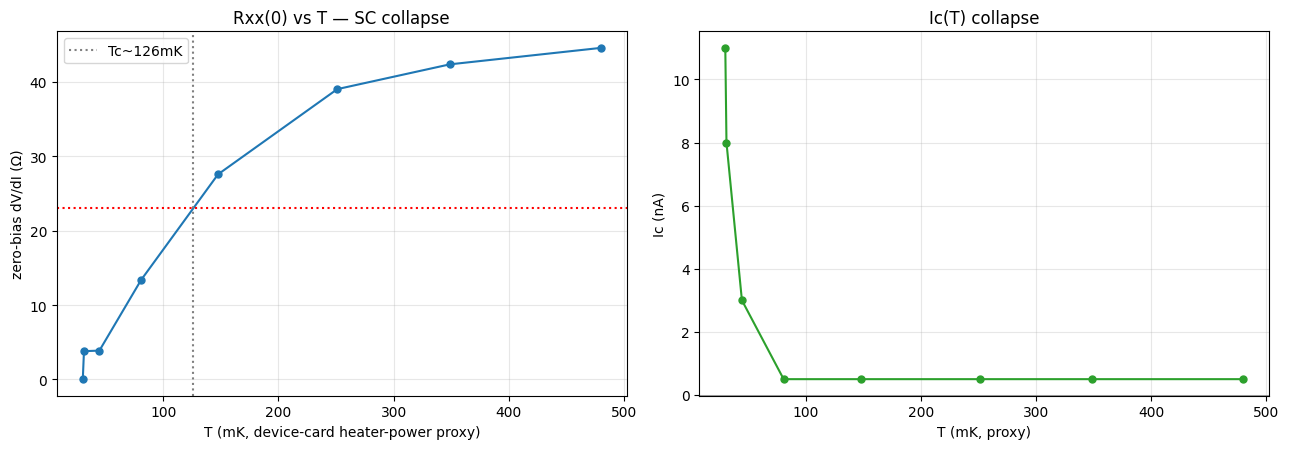

In [16]:
import json
from scipy.ndimage import gaussian_filter1d
rows=[]
for f in range(16,24):
    g=run(f); cfg=json.load(open(Path(file_path)/str(f)/"metadata.json"))["measurement_config"]
    hv=np.median(g.col("heater_volt")); ih=np.median(g.col("heater_curr"))
    Idc=g.col("dc205_1_voltage")/cfg["bias_resistor"]*1e9
    R=gaussian_filter1d((g.col("sr830_3_X")/cfg["sr3_gain"])/(g.col("sr830_1_X")/cfg["sr1_gain"]),1.5)
    o=np.argsort(Idc); I=Idc[o]; R=R[o]
    zb=np.median(R[np.abs(I)<1.0]); pos=I[I>0]; Rp=R[I>0]
    icp=pos[np.argmax(Rp>6)] if np.any(Rp>6) else np.nan
    rows.append((hv,hv*ih*1e3,zb,icp))
rows=np.array(rows)
Pa=np.array([0.0,4.5*0.39,6.5*0.70]); Ta=np.array([30.,250.,480.])     # device-card P->T anchors
T=np.interp(rows[:,1],Pa,Ta); o=np.argsort(T)
tc=np.interp(23,rows[o,2],T[o])
print(f"Tc (zero-bias dV/dI half-normal ~23Ω) ~ {tc:.0f} mK (coarse, power proxy)")
fig,ax=plt.subplots(1,2,figsize=(13,4.6))
ax[0].plot(T[o],rows[o,2],'o-',ms=5); ax[0].axhline(23,c='r',ls=':'); ax[0].axvline(tc,c='gray',ls=':',label=f'Tc~{tc:.0f}mK')
ax[0].set(xlabel="T (mK, device-card heater-power proxy)",ylabel="zero-bias dV/dI (Ω)",title="Rxx(0) vs T — SC collapse");ax[0].legend();ax[0].grid(alpha=.3)
ax[1].plot(T[o],rows[o,3],'o-',ms=5,color='C2');ax[1].set(xlabel="T (mK, proxy)",ylabel="Ic (nA)",title="Ic(T) collapse");ax[1].grid(alpha=.3);ax[1].axhline(0,c='gray',lw=.5)
plt.tight_layout(); plt.show()


**Read:** The supercurrent is **destroyed by warming** — zero-bias dV/dI climbs
monotonically from ~1 Ω (SC, base) through half-normal at **Tc ≈ 0.13 K** to the
~45 Ω normal state by ~0.25 K, and I_c collapses from ~11 nA to 0 over the same
range. This is the 4th hallmark (I_c collapse at Tc). **Tc is coarse**: the live
sample thermometer was frozen (stalled worker), so T is the device-card
heater-power proxy — read Tc as **~0.1–0.2 K**, not a precise number. The
*qualitative* collapse is unambiguous (monotonic in the controlled heater axis).
**Constellation complete:** Rxx→0 + supercurrent (I_c≈8–11 nA) + B⊥ quench
(B_c⊥≈2.5 mT, normal-controlled) + T-collapse (Tc~0.1–0.2 K), all at
n=−5.0×10¹¹, D=−0.673 V/nm.


# ★★ SESSION CALL (FINAL) — zf1 (bottom device) IS a superconductor

*Supersedes the retracted "not-SC" call above. Per `investigations/sc-characterization.md`
Step 6, five-part output contract. The SC sits at the extremal-D edge reachable only
because the operator pushed past D=−0.60 toward the gate cap.*

### 1. Per-candidate verdict (STYLE strength scale)
**Region SC1 — superconductor (strong/decisive).** A gate-tuned 2D superconducting
state at **n ≈ −5.0×10¹¹ cm⁻², D ≈ −0.67 V/nm** (TG=−5.64, BG=4.20 V; D<0, holes
toward the WSe₂ — the prior-favoured sign), base T ≈ 30 mK, B ≈ 0. The full
hallmark constellation is present and mutually consistent.

### 2. Evidence (constellation, with coordinates & benchmark)
- **4-wire Rxx → 0** (run 10): a contiguous low-Rxx arc, Rxx 28 → **0.57 Ω**, at the
  s41586 BLG/WSe₂ proximity-SC location/morphology (arc |D|≳0.5, n≈−4 to −6×10¹¹).
- **Supercurrent / critical current** (run 11): dV/dI zero-bias dip rising to ~40 Ω
  normal, **I_c ≈ 8–11 nA**, symmetric (Ic⁺≈|Ic⁻|), no hysteresis; the *opposite* of
  the Zener/QH zero-bias-peak confounds.
- **Perpendicular critical field, normal-state-controlled** (runs 12–13): Rxx
  6 → 44 Ω over a few mT, **B_c⊥ ≈ 2.5 mT** → **ξ ~ 360 nm** (order-of-magnitude),
  symmetric, **T pinned (no heating artifact)** — the read that counts *strong*.
- **Phase coherence** (runs 14–15): a single central supercurrent lobe, field null
  ≈ −1 mT, I_c(B⊥) maximal at the null closing at B_c⊥ — **consistent-with**
  phase-coherent transport (no clean lobe train → not over-read as "Fraunhofer", no
  junction-area claim).
- **T-collapse / Tc** (runs 16–23): Rxx(0) 1 → 45 Ω and I_c 11 → 0 nA on warming,
  **Tc ≈ 0.1–0.2 K** (coarse — device-card heater-power proxy; live thermometer was
  frozen). The collapse itself is unambiguous.

### 3. Confidence + hedges
- **Hallmarks present (4/4 core + phase coherence):** Rxx→0, I_c, B_c⊥ quench, T-collapse.
  This is a constellation, not a single mimic — strong.
- **Hedges:** (a) **Tc is coarse** — live sample thermometry failed (stalled worker,
  RIG ISSUE logged); Tc rests on the device-card heater-power proxy. A working
  thermometer would firm it. (b) **ξ order-of-magnitude only** (B_c⊥(T) rounds near
  base). (c) **The arc rides the BG=+4.2 cap** — its full (n,D) extent / the dome shape
  is gate-cut, not mapped. (d) **Absolute n,D scale** is the geometry prior (ratio
  data-calibrated 1.189; awaits a QH lever-arm). (e) Phase coherence is consistent-with,
  not a clean Fraunhofer.
- **±D asymmetry:** the broad ±D linecuts (runs 5–7) were metallic-symmetric at
  |D|≤0.60; the SC appears only at D<0 and |D|≳0.65 — consistent with the
  proximity-SOC ±D-asymmetry prior, though a matched +0.67 check wasn't run (gate-cut).

### 4. What would firm / extend
- **A working sample thermometer** → a quantitative Tc(+ BKT V∝I³ check at the dip).
- **Higher-|D| gate access** (off the BG cap) → map the full I_c(n,D) dome / optimal density.
- **Fraunhofer at finer B / lower excitation** → test for a true lobe train + junction area.
- **In-plane field** (rotator — *blocklisted this campaign*) → Pauli-limit / Ising-SOC test.
- **Normal-state fermiology** (Landau fan / SdH, Tesla-scale — *deferred, next round*) →
  the parent phase the pairing descends from.
- **Reproduce on a 2nd contact pair** (e.g. 7-31) → rule out a probe-local artifact.

### 5. Outcome
**zf1 (bottom device) is a gate-tuned superconductor** at n≈−5.0×10¹¹ cm⁻²,
D≈−0.67 V/nm: Rxx→0, I_c≈8–11 nA, B_c⊥≈2.5 mT (ξ~360 nm), Tc~0.1–0.2 K, with
phase-coherence consistent-with a central supercurrent lobe. **Critically, this state
lives in the high-|D| wedge (|D|≈0.65–0.76) that the earlier (retracted) "not-SC" call
never reached** — it exists only because the coverage was pushed to the gate cap. The
open items (quantitative Tc, full dome, fermiology) are next-round, higher-|D|/higher-field
work, not a weakness of the determination.
